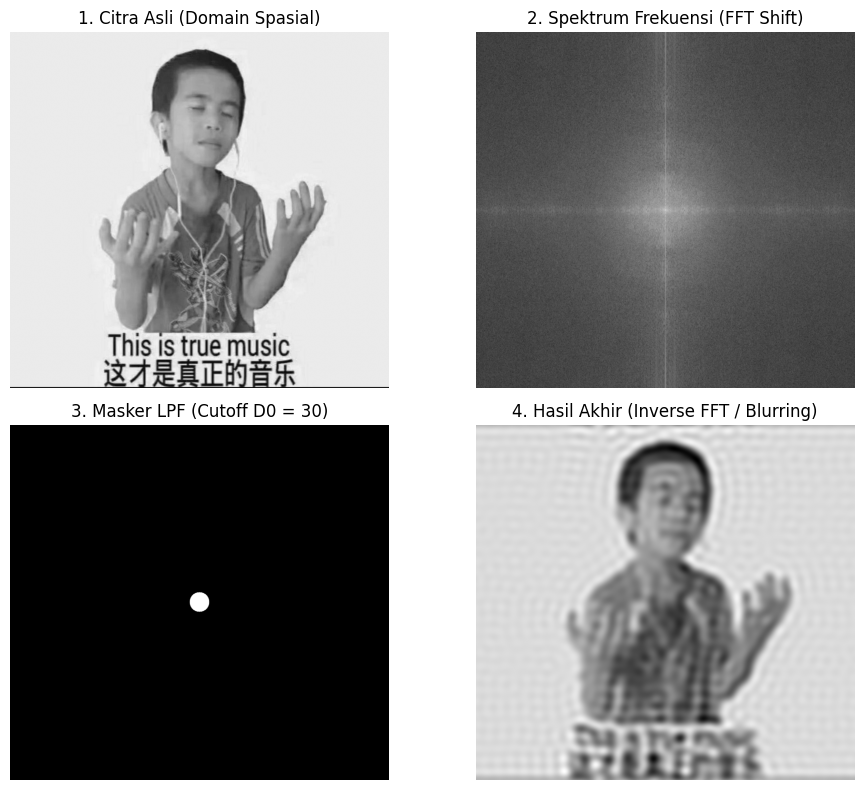

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 1. Baca citra dalam format grayscale
img = cv2.imread('image.png', cv2.IMREAD_GRAYSCALE)
if img is None:
    raise FileNotFoundError("File gambar tidak ditemukan, pastikan path gambar benar.")

# 2. Transformasi Fourier 2D (FFT)
f_transform = np.fft.fft2(img)

# 3. Geser frekuensi rendah (DC Component) ke pusat spektrum (FFT Shift)
f_shift = np.fft.fftshift(f_transform)

# 4. Spektrum Magnitudo (di-skala logaritmik agar detail terlihat)
magnitude_spectrum = 20 * np.log(np.abs(f_shift) + 1)

# 5. Membuat Low Pass Filter (LPF) Lingkaran sederhana
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
D0 = 30
mask = np.zeros((rows, cols), np.uint8)
cv2.circle(mask, (ccol, crow), D0, 1, -1)

# 6. Perkalian spektrum frekuensi dengan masker filter
f_shift_filtered = f_shift * mask

# 7. Inverse FFT (Kembalikan dari domain frekuensi ke domain spasial)
f_ishift = np.fft.ifftshift(f_shift_filtered)
img_back = np.fft.ifft2(f_ishift)
img_back = np.abs(img_back)

# 8. Visualisasi Tahapan
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Citra Asli (Domain Spasial)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('2. Spektrum Frekuensi (FFT Shift)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(mask * 255, cmap='gray')
plt.title(f'3. Masker LPF (Cutoff D0 = {D0})')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_back, cmap='gray')
plt.title('4. Hasil Akhir (Inverse FFT / Blurring)')
plt.axis('off')

plt.tight_layout()
plt.show()